# 02 — Engenharia de features temporais

## Fluxo Bronze → Silver → Gold

- **Bronze** fornece os calendários completos e preservados.
- **Silver** é a base reconciliada e auditada por data.
- **Gold** combina consumo, calendário e cardápio e recebe as features para previsão.

O horizonte inicial é de sete dias. Para cada exemplo histórico de treino, as variáveis de consumo e popularidade são calculadas com registros estritamente anteriores à origem (`sexta-feira anterior à semana-alvo`). Para um lote futuro de validação, a função aceita uma única origem comum e não usa resultados observados dentro da janela de teste. Calendário e cardápio da data-alvo são conhecidos antecipadamente.

`consumo_total_csv_recebido` nunca entra nos preditores. Ausências históricas permanecem ausentes; não são convertidas em consumo zero. Features constantes ficam identificadas no catálogo, mas devem ser removidas dentro do pipeline quando forem constantes no treino do fold. A codificação categórica e imputação serão ajustadas dentro dos folds do Notebook 03.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Não localizei a raiz F:/PRODUTO_MESTRADO.")
LINE_ID = "consumo_cardapio_calendario"
LINE_RESULTS = ROOT / "resultados" / "linhas" / LINE_ID
FEATURES_DIR = ROOT / "data" / "experimentos" / LINE_ID / "features"
sys.path.insert(0, str(ROOT / "scripts"))
from feature_engineering_temporal import (
    read_gold, read_calendar, build_training_feature_table, build_features_for_targets,
    get_predictor_columns, MENU_CATEGORICAL,
)

OUT = FEATURES_DIR
OUT.mkdir(parents=True, exist_ok=True)
RESULTS = LINE_RESULTS / "02_engenharia_features"
RESULTS.mkdir(parents=True, exist_ok=True)
gold = read_gold()
calendar = read_calendar()
print(f"Gold (Silver → Gold): {len(gold)} datas; calendário Bronze: {len(calendar)} dias")


Gold (Silver → Gold): 868 datas; calendário Bronze: 1461 dias


In [2]:
# Materializa uma amostra supervisionada por data-alvo com features point-in-time
features = build_training_feature_table(gold, calendar, horizon_days=7)
predictors = get_predictor_columns(features)
metadata_columns = ["data_alvo", "origem_previsao", "ultima_data_consumo_historico"]
print(f"Amostras: {len(features)} | Features candidatas: {len(predictors)}")
display(features[["data_alvo", "origem_previsao", "consumo_total", "ultima_data_consumo_historico"] + predictors[:12]].head(8))


Amostras: 500 | Features candidatas: 71


,data_alvo,origem_previsao,consumo_total,ultima_data_consumo_historico,ano,mes,dia_mes,dia_semana_num,semana_ano,is_inicio_mes,is_fim_mes,dia_semana_sin,dia_semana_cos,mes_sin,mes_cos,dia_ano_sin
0,2023-02-06,2023-02-03,118.0,NaT,2023,2,6,0,6,0,0,0.000000,1.000000,0.5,0.866025,0.580455
1,2023-02-07,2023-02-03,110.0,NaT,2023,2,7,1,6,0,0,0.781831,0.623490,0.5,0.866025,0.594376
2,2023-02-08,2023-02-03,109.0,NaT,2023,2,8,2,6,0,0,0.974928,-0.222521,0.5,0.866025,0.608121
3,2023-02-09,2023-02-03,92.0,NaT,2023,2,9,3,6,0,0,0.433884,-0.900969,0.5,0.866025,0.621687
4,2023-02-10,2023-02-03,97.0,NaT,2023,2,10,4,6,0,0,-0.433884,-0.900969,0.5,0.866025,0.635068
5,2023-02-13,2023-02-10,111.0,2023-02-09,2023,2,13,0,7,0,0,0.000000,1.000000,0.5,0.866025,0.674069
6,2023-02-14,2023-02-10,120.0,2023-02-09,2023,2,14,1,7,0,0,0.781831,0.623490,0.5,0.866025,0.686676
7,2023-02-15,2023-02-10,104.0,2023-02-09,2023,2,15,2,7,0,0,0.974928,-0.222521,0.5,0.866025,0.699079


In [3]:
# Auditoria de vazamento, alvo e separação entre preditores e campos de controle
received_only = {"consumo_total_csv_recebido", "fonte_consumo", "status_reconciliacao_consumo", "flag_consumo_reconciliado"}
assert "consumo_total" not in predictors
assert not (set(predictors) & received_only)
assert features["data_alvo"].is_unique
assert features["consumo_total"].notna().all()
origin = pd.to_datetime(features["origem_previsao"])
last_history = pd.to_datetime(features["ultima_data_consumo_historico"], errors="coerce")
leaks = last_history.notna() & last_history.ge(origin)
assert not leaks.any(), f"Vazamento temporal detectado em {int(leaks.sum())} amostras"
lead_days = (features["data_alvo"] - origin).dt.days
assert features["data_alvo"].dt.dayofweek.lt(5).all()
assert origin.dt.dayofweek.eq(4).all()
assert lead_days.between(3, 7).all()

audit = pd.DataFrame({
    "checagem": ["amostras", "preditores candidatos", "preditores constantes na amostra", "vazamentos históricos", "alvo ausente", "campo bruto recebido entre preditores"],
    "resultado": [len(features), len(predictors), sum(features[c].nunique(dropna=True) <= 1 for c in predictors), int(leaks.sum()), int(features["consumo_total"].isna().sum()), int(bool(set(predictors) & received_only))],
})
display(audit)


,checagem,resultado
0,amostras,500
1,preditores candidatos,71
2,preditores constantes na amostra,5
3,vazamentos históricos,0
4,alvo ausente,0
5,campo bruto recebido entre preditores,0


In [4]:
# Inventário de features e taxas de ausência
def feature_group(name):
    if name in MENU_CATEGORICAL or name.startswith("cardapio_") or name.startswith("popularidade_historica_") or name.startswith("n_historico_proteina") or name.startswith("n_historico_preparo"):
        return "cardápio / preferência histórica"
    if name.startswith(("dias_desde_feriado", "dias_ate_proximo_feriado", "is_emenda_ou_ponte")):
        return "calendário"
    if name.startswith(("consumo_", "n_observacoes_", "dias_desde_", "tendencia_")):
        return "histórico de consumo"
    if name.startswith(("evento_", "is_", "status_", "dias_")):
        return "calendário"
    if "_x_" in name:
        return "interação"
    if name in {"ano", "mes", "dia_mes", "dia_semana_num", "semana_ano"} or name.endswith(("_sin", "_cos")):
        return "data / sazonalidade"
    return "outro"

feature_dictionary = pd.DataFrame([
    {"feature": column, "grupo": feature_group(column), "tipo": str(features[column].dtype),
     "percentual_ausente": round(float(features[column].isna().mean() * 100), 2),
     "valores_distintos_na_amostra": int(features[column].nunique(dropna=True)),
     "constante_na_amostra": bool(features[column].nunique(dropna=True) <= 1),
     "disponibilidade": "data-alvo conhecida" if feature_group(column) in {"data / sazonalidade", "calendário", "interação"} or column in MENU_CATEGORICAL or column.startswith("cardapio_") else "somente observações anteriores à origem"}
    for column in predictors
])
display(feature_dictionary.groupby("grupo", as_index=False).agg(quantidade=("feature", "count"), features=("feature", lambda s: ", ".join(s))))
display(feature_dictionary.sort_values(["grupo", "feature"]))
constant_features = feature_dictionary.loc[feature_dictionary["constante_na_amostra"], ["feature", "grupo", "valores_distintos_na_amostra"]]
print(f"Features constantes na amostra histórica: {len(constant_features)}; os pipelines devem removê-las quando constantes no treino do fold.")
display(constant_features)


,grupo,quantidade,features
0,calendário,20,"is_inicio_mes, is_fim_mes, status_legal, event..."
1,cardápio / preferência histórica,12,"prato_principal, tipo_proteina_principal, tipo..."
2,data / sazonalidade,11,"ano, mes, dia_mes, dia_semana_num, semana_ano,..."
3,histórico de consumo,25,"dias_desde_fim_ferias_recesso, consumo_lag_1_o..."
4,interação,3,"dia_semana_x_status_letivo, dia_semana_x_prote..."


,feature,grupo,tipo,percentual_ausente,valores_distintos_na_amostra,constante_na_amostra,disponibilidade
24,dias_ate_inicio_ferias_recesso,calendário,float64,0.0,133,False,data-alvo conhecida
21,dias_ate_proximo_feriado,calendário,float64,0.0,60,False,data-alvo conhecida
20,dias_desde_feriado_anterior,calendário,float64,0.0,104,False,data-alvo conhecida
27,evento_avaliacao_ou_reavaliacao,calendário,bool,0.0,2,False,data-alvo conhecida
28,evento_conselho_ou_reuniao,calendário,bool,0.0,2,False,data-alvo conhecida
...,...,...,...,...,...,...,...
52,n_observacoes_janela_5,histórico de consumo,int64,0.0,3,False,somente observações anteriores à origem
57,tendencia_media_recente_vs_anterior,histórico de consumo,float64,2.0,107,False,somente observações anteriores à origem
42,dia_semana_x_preparo,interação,object,1.4,47,False,data-alvo conhecida
41,dia_semana_x_proteina,interação,object,1.4,28,False,data-alvo conhecida


Features constantes na amostra histórica: 5; os pipelines devem removê-las quando constantes no treino do fold.


,feature,grupo,valores_distintos_na_amostra
16,is_evento_calendario,calendário,1
22,is_emenda_ou_ponte_explicita,calendário,1
23,is_periodo_ferias_ou_recesso,calendário,1
30,evento_recesso,calendário,1
31,evento_sabado_letivo,calendário,1


,feature,percentual_ausente
46,consumo_lag_8_observacoes,2.0
57,tendencia_media_recente_vs_anterior,2.0
60,consumo_ultimo_mesmo_dia_semana,1.2
62,consumo_mediana_ultimas_2_ocorrencias_mesmo_di...,1.2
61,consumo_media_ultimas_2_ocorrencias_mesmo_dia_...,1.2
65,consumo_media_ultimas_8_ocorrencias_mesmo_dia_...,1.2
64,consumo_mediana_ultimas_4_ocorrencias_mesmo_di...,1.2
66,consumo_mediana_ultimas_8_ocorrencias_mesmo_di...,1.2
63,consumo_media_ultimas_4_ocorrencias_mesmo_dia_...,1.2
53,consumo_media_ultimas_10_observacoes,1.0


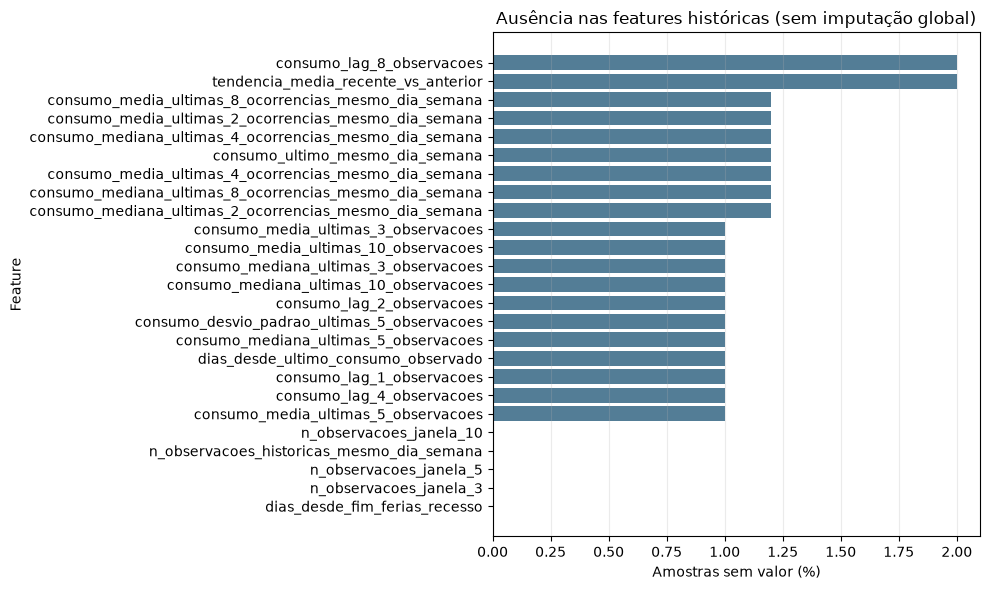

In [5]:
# Ausências das variáveis de histórico: início da série não vira zero
history_features = feature_dictionary.loc[feature_dictionary["grupo"].eq("histórico de consumo"), "feature"].tolist()
missing_history = feature_dictionary.loc[feature_dictionary["grupo"].eq("histórico de consumo"), ["feature", "percentual_ausente"]].sort_values("percentual_ausente", ascending=False)
display(missing_history)
fig, ax = plt.subplots(figsize=(10, 6))
plot_missing = missing_history.sort_values("percentual_ausente")
ax.barh(plot_missing["feature"], plot_missing["percentual_ausente"], color="#537D96")
ax.set(title="Ausência nas features históricas (sem imputação global)", xlabel="Amostras sem valor (%)", ylabel="Feature")
ax.grid(axis="x", alpha=.25); fig.tight_layout()
fig.savefig(RESULTS / "ausencia_features_historicas.png", dpi=160, bbox_inches="tight")
plt.show()


In [6]:
# Confirmação de que a API também cria lote de validação com origem fixa
validation_origin = pd.Timestamp("2026-01-02")
future_targets = gold.loc[(gold["data"] > validation_origin) & (gold["data"] <= validation_origin + pd.Timedelta(days=7)) & gold["data"].dt.dayofweek.lt(5), "data"]
if len(future_targets):
    fixed_origin_features = build_features_for_targets(gold, calendar, future_targets, validation_origin, horizon_days=7)
    assert pd.to_datetime(fixed_origin_features["origem_previsao"]).nunique() == 1
    fixed_latest = pd.to_datetime(fixed_origin_features["ultima_data_consumo_historico"], errors="coerce")
    assert not (fixed_latest.notna() & fixed_latest.ge(validation_origin)).any()
    print(f"Lote futuro: {len(fixed_origin_features)} datas, origem fixa {validation_origin.date()}, vazamento=0")
else:
    print("Não há datas de consumo observadas nessa janela demonstrativa; a função aceita qualquer lote futuro coberto por Gold e calendário.")


Lote futuro: 5 datas, origem fixa 2026-01-02, vazamento=0


In [7]:
# Grava a Gold de features e os artefatos de auditoria/dicionário
feature_path = OUT / "features_supervisionadas_horizonte_7d.csv"
dictionary_path = OUT / "dicionario_features_horizonte_7d.csv"
audit_path = OUT / "auditoria_features_horizonte_7d.csv"
features.to_csv(feature_path, index=False, encoding="utf-8-sig")
feature_dictionary.to_csv(dictionary_path, index=False, encoding="utf-8-sig")
audit.to_csv(audit_path, index=False, encoding="utf-8-sig")
print(f"Gold features: {feature_path}")
print(f"Dicionário: {dictionary_path}")
print(f"Auditoria: {audit_path}")


Gold features: F:\PRODUTO_MESTRADO\data\experimentos\consumo_cardapio_calendario\features\features_supervisionadas_horizonte_7d.csv
Dicionário: F:\PRODUTO_MESTRADO\data\experimentos\consumo_cardapio_calendario\features\dicionario_features_horizonte_7d.csv
Auditoria: F:\PRODUTO_MESTRADO\data\experimentos\consumo_cardapio_calendario\features\auditoria_features_horizonte_7d.csv


## Critérios para o Notebook 03

1. Em cada corte temporal, treinar apenas com alvos observados até a origem do corte.
2. Construir todos os alvos do bloco de validação com uma única origem fixa usando `build_features_for_targets`; nunca recalcular lags usando consumos da própria janela de validação.
3. Ajustar imputação, escalonamento e codificação categórica dentro do pipeline de cada fold.
4. Comparar todos os modelos nas mesmas datas. A tabela supervisionada desta Gold é para exemplos históricos point-in-time; o lote de teste precisa ser recriado por origem do fold.
